In [1]:
!pip install datasets transformers torch scikit-learn pandas matplotlib xgboost
!pip install --upgrade datasets huggingface_hub fsspec

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.6 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 1.9 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 2.3 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 30.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 7.8 MB/s eta 0:00:000:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 84.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 11.7 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.9.41
    Uninstalling nvidia-nvjitlink-cu12-12.9.41:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.9.41
  Attempting uninstall: nvidia-curand-cu12
    Found existing

**Import các thư viện cần thiết**

In [2]:
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

from matplotlib_venn import venn2
from wordcloud import WordCloud

from datasets import load_dataset, Dataset, DatasetDict
from transformers import RobertaTokenizer, RobertaForSequenceClassification, TrainingArguments, Trainer

2025-07-03 14:00:49.700684: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1751551249.927600      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1751551249.987736      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


**Tải các tài nguyên NLTK**

In [3]:
# Tải các tài nguyên NLTK
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /usr/share/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /usr/share/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

# Preprocessing

**Tiền xử lý văn bản**

In [4]:
# Hàm tiền xử lý văn bản
def preprocess_text_for_counter(text):
    # Chuyển thành chữ thường
    text = text.lower()
    # Loại bỏ dấu câu
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tách từ
    tokens = word_tokenize(text)
    # Loại bỏ stop words
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words and word.isalpha()]
    return tokens

def preprocess_text(text):
    tokens = preprocess_text_for_counter(text)
    return ' '.join(tokens)

**Ánh xạ nhãn từ [1,5] -> [0,4]**

In [5]:
# Hàm ánh xạ nhãn từ [1, 5] thành [0, 4]
def remap_labels(examples):
    examples['class_index'] = [label - 1 for label in examples['class_index']]
    return examples

**Tải bộ dữ liệu**

In [6]:
# Tải bộ dữ liệu
dataset = load_dataset("yassiracharki/Amazon_Reviews_for_Sentiment_Analysis_fine_grained_5_classes")
print(dataset)

README.md: 0.00B [00:00, ?B/s]

train.csv:   0%|          | 0.00/1.34G [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/290M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3000000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/650000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['class_index', 'review_title', 'review_text'],
        num_rows: 3000000
    })
    test: Dataset({
        features: ['class_index', 'review_title', 'review_text'],
        num_rows: 650000
    })
})


**Giảm kích thước tập train và test**

In [7]:
# Giảm kích thước tập train và test (1%)
sample_size = 0.01
df_train = pd.DataFrame(dataset['train'])
_, df_train_sample = train_test_split(df_train, test_size=sample_size, stratify=df_train['class_index'], random_state=42)
df_test = pd.DataFrame(dataset['test'])
_, df_test_sample = train_test_split(df_test, test_size=sample_size, stratify=df_test['class_index'], random_state=42)

**Tạo tập validation cho Roberta**

In [8]:
# Chia tập train_sample thành train và validation (80% train, 20% validation)
df_train_new, df_validation = train_test_split(df_train_sample, test_size=0.2, stratify=df_train_sample['class_index'], random_state=42)

**Vẽ biểu đồ Pie tỷ lệ nhãn**

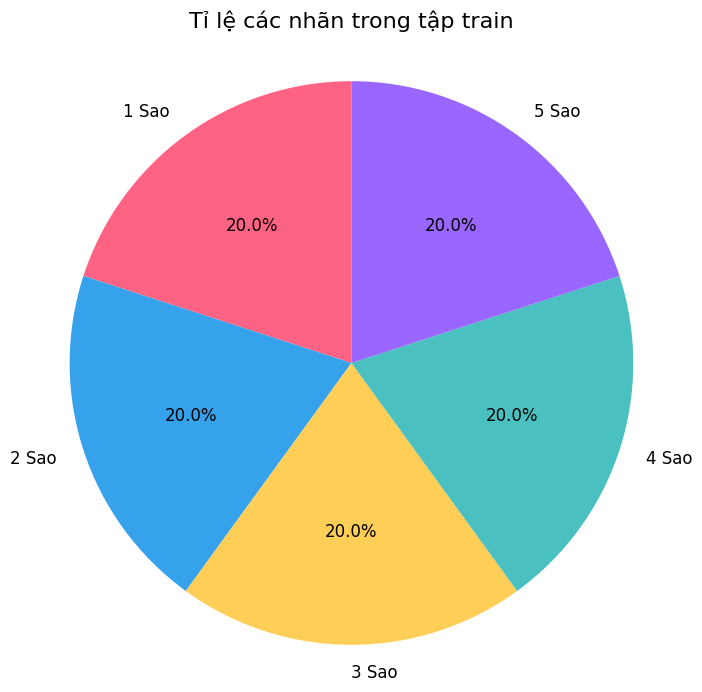

In [9]:
label_counts = df_train_sample['class_index'].value_counts(normalize=True) * 100  # Tính phần trăm
label_counts = label_counts.sort_index()  # Sắp xếp theo nhãn [0, 1, 2, 3, 4]

label_names = ["1 Sao", "2 Sao", "3 Sao", "4 Sao", "5 Sao"]

# Vẽ pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    label_counts,
    labels=label_names,
    autopct='%1.1f%%',
    colors=['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0', '#9966FF'],
    startangle=90,
    textprops={'fontsize': 12}
)
plt.title("Tỉ lệ các nhãn trong tập train", fontsize=16, pad=20)
plt.axis('equal')  # Đảm bảo hình tròn
plt.show()

**Phân tích tần suất từ trong tập huấn luyện**

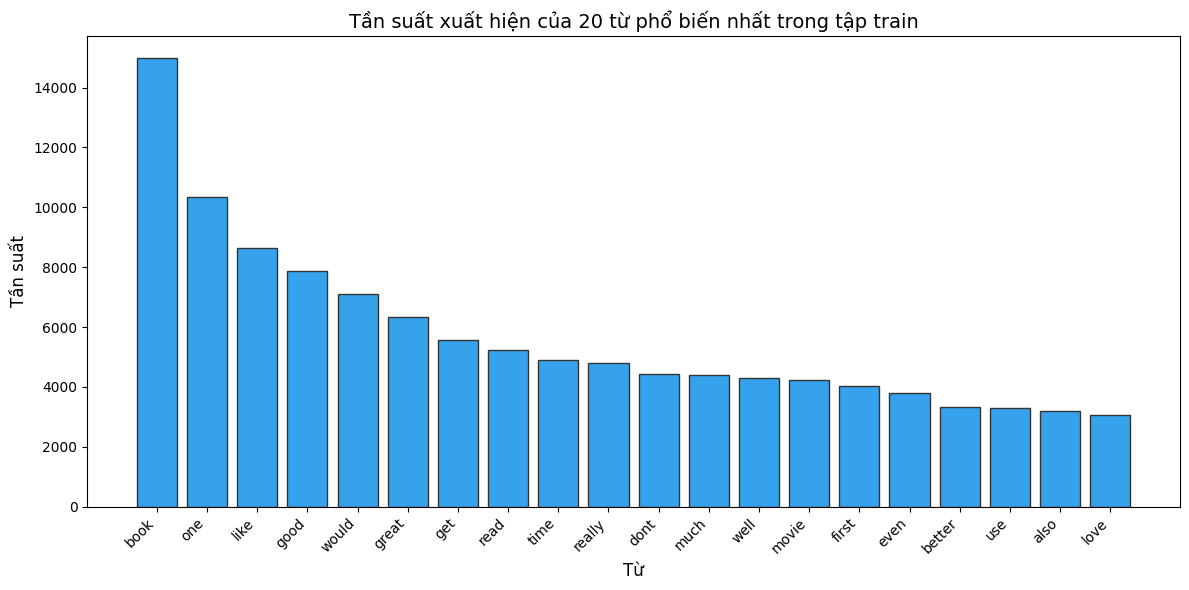

In [10]:
# Áp dụng tiền xử lý cho tất cả các review
all_words = []
for text in df_train_sample['review_text']:
    all_words.extend(preprocess_text_for_counter(text))

# Đếm tần suất từ
word_counts = Counter(all_words)

# Lấy 20 từ phổ biến nhất
top_20_words = word_counts.most_common(20)
words, frequencies = zip(*top_20_words)

# Vẽ biểu đồ cột
plt.figure(figsize=(12, 6))
plt.bar(words, frequencies, color='#36A2EB', edgecolor='#333333')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.xlabel('Từ', fontsize=12)
plt.ylabel('Tần suất', fontsize=12)
plt.title('Tần suất xuất hiện của 20 từ phổ biến nhất trong tập train', fontsize=14)
plt.tight_layout()
plt.show()

**Trích xuất TF-IDF và logistic regression**

In [11]:
# Chuyển DataFrame thành Dataset để dùng map
train_dataset = Dataset.from_pandas(df_train_new)
test_dataset = Dataset.from_pandas(df_test_sample)
val_dataset = Dataset.from_pandas(df_validation)

train_dataset = train_dataset.map(remap_labels, batched=True)
test_dataset = test_dataset.map(remap_labels, batched=True)
val_dataset = val_dataset.map(remap_labels, batched=True)

Map:   0%|          | 0/24000 [00:00<?, ? examples/s]

Map:   0%|          | 0/6500 [00:00<?, ? examples/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

**Tiền xử lý dữ liệu**

In [12]:
# 2. Chuẩn bị dữ liệu
X_train = train_dataset['review_text']
y_train = train_dataset['class_index']
X_test = test_dataset['review_text']
y_test = test_dataset['class_index']

X_train_preprocessed = [preprocess_text(text) for text in X_train]
X_test_preprocessed = [preprocess_text(text) for text in X_test]

**Đếm số lượng từ trong tập dữ liệu**

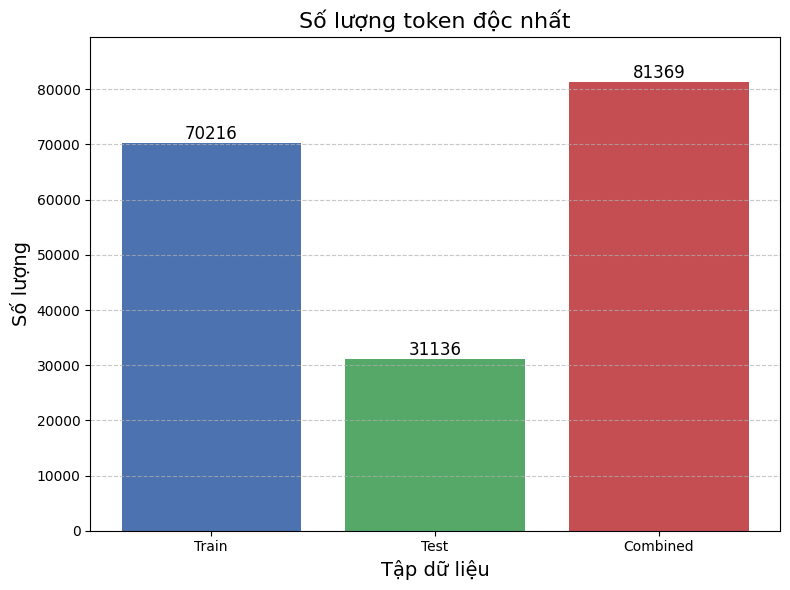

In [13]:
def count_unique_words(data):
    unique_words = set()
    for text in data:
        # Tokenize văn bản
        tokens = word_tokenize(str(text))  # Chuyển thành chuỗi để xử lý trường hợp không phải string
        # Thêm các token vào tập hợp
        unique_words.update(tokens)
    return len(unique_words), unique_words

# Đếm từ độc nhất
train_unique_count, _ = count_unique_words(X_train_preprocessed)
test_unique_count, _ = count_unique_words(X_test_preprocessed)
combined_unique_count, _ = count_unique_words(X_train_preprocessed + X_test_preprocessed)

# Tạo dữ liệu cho biểu đồ
labels = ['Train', 'Test', 'Combined']
counts = [train_unique_count, test_unique_count, combined_unique_count]

# Vẽ biểu đồ cột
plt.figure(figsize=(8, 6))
bars = plt.bar(labels, counts, color=['#4C72B0', '#55A868', '#C44E52'])

# Thêm nhãn trên đầu mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 5, str(height), ha='center', va='bottom', fontsize=12)

plt.title("Số lượng token độc nhất", fontsize=16)
plt.ylabel("Số lượng", fontsize=14)
plt.xlabel("Tập dữ liệu", fontsize=14)
plt.ylim(0, max(counts) + max(counts)*0.1)  # Thêm khoảng trống phía trên
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


**Biểu diễn dưới dạng biểu đồ venn**

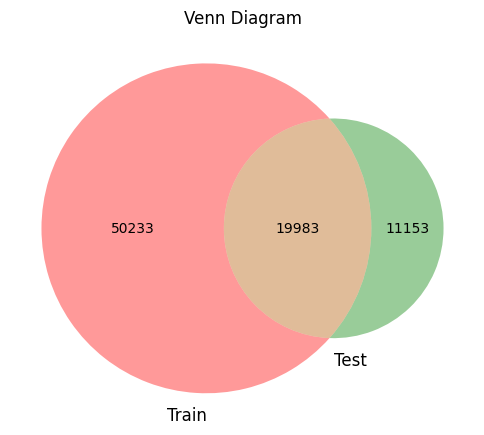

In [14]:
_, train_words = count_unique_words(X_train_preprocessed)
_, test_words = count_unique_words(X_test_preprocessed)

plt.figure(figsize=(6, 6))
venn2([train_words, test_words], set_labels=('Train', 'Test'))
plt.title("Venn Diagram")
plt.show()

**WordCloud theo từng lớp**

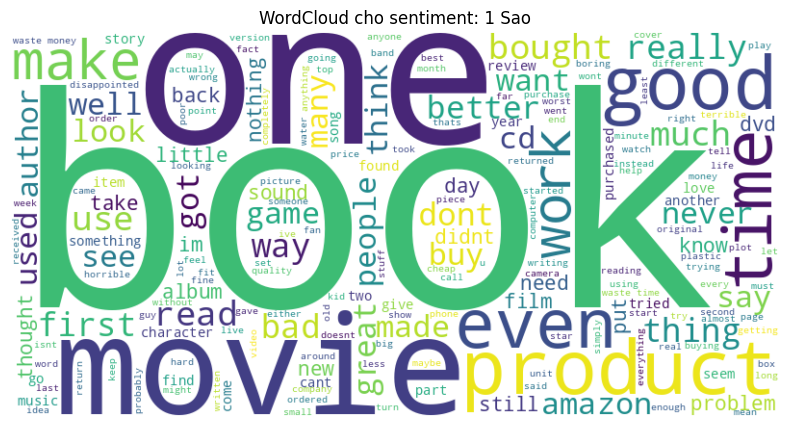

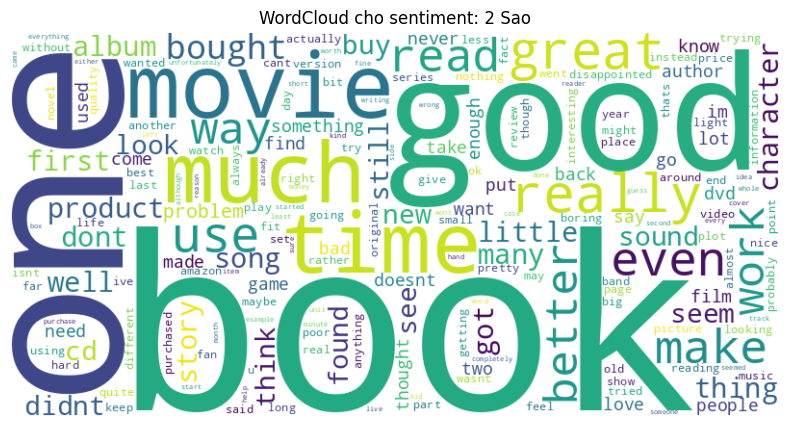

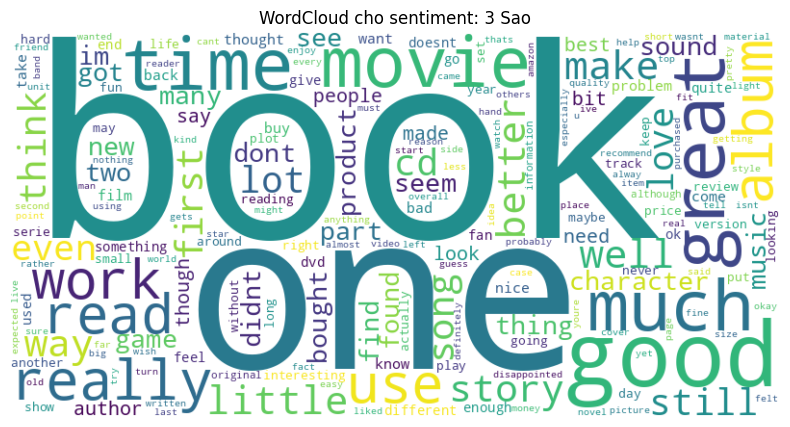

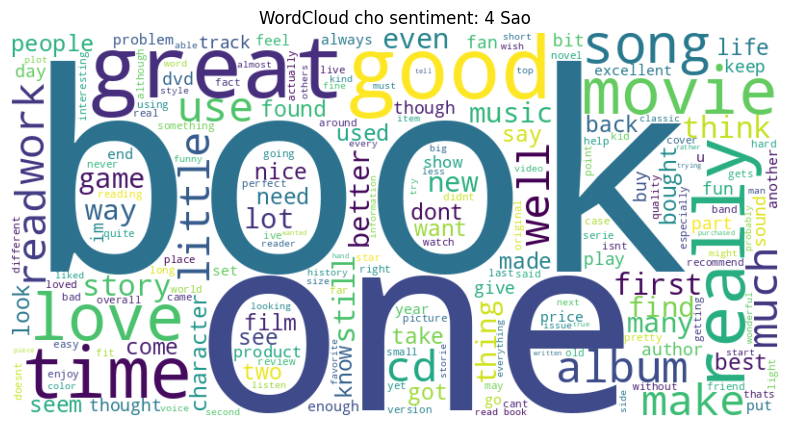

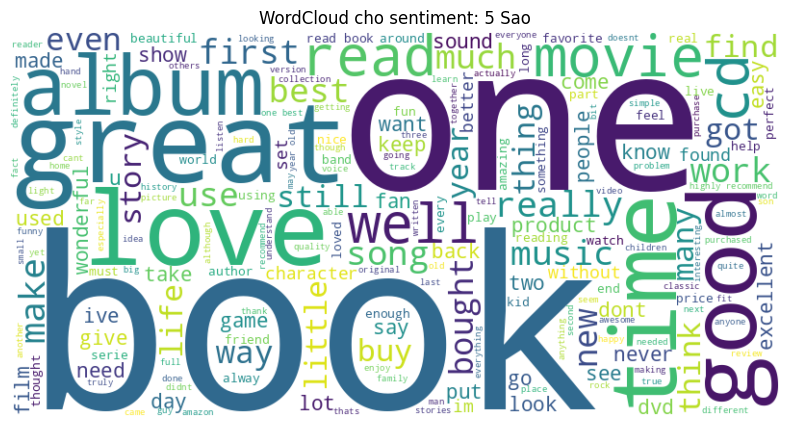

In [15]:
def wordcloud_by_sentiment(X, y, sentiment_label):
    text = ' '.join([
        str(X[i]) for i in range(len(y)) if y[i] == sentiment_label
    ])
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis("off")
    plt.title(f"WordCloud cho sentiment: {sentiment_label + 1} Sao")
    plt.show()

# Ví dụ:
wordcloud_by_sentiment(X_train_preprocessed, y_train, sentiment_label=0) 
wordcloud_by_sentiment(X_train_preprocessed, y_train, sentiment_label=1)
wordcloud_by_sentiment(X_train_preprocessed, y_train, sentiment_label=2) 
wordcloud_by_sentiment(X_train_preprocessed, y_train, sentiment_label=3)
wordcloud_by_sentiment(X_train_preprocessed, y_train, sentiment_label=4) 

**Biểu đồ độ dài văn bản theo sentiment**

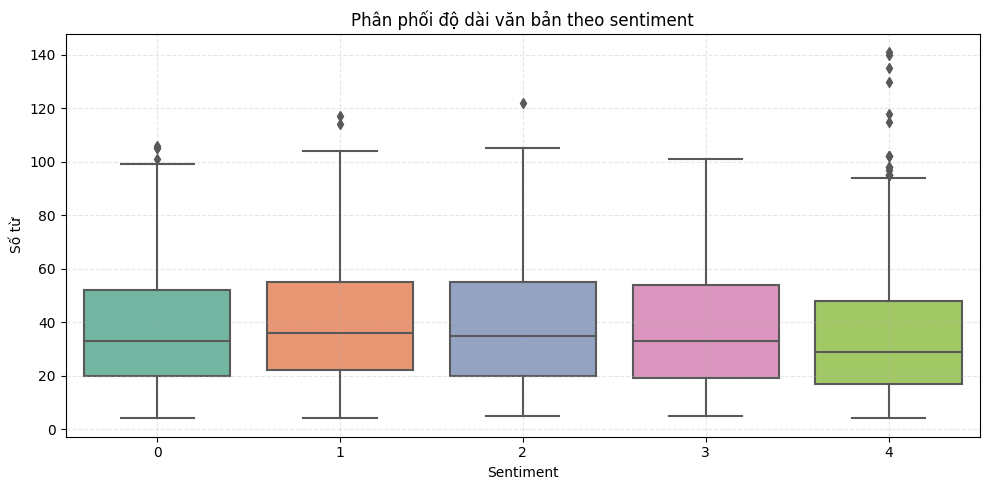

In [16]:
def plot_text_length_by_class(X, y):
    df = pd.DataFrame({'text': X, 'label': y})
    df['length'] = df['text'].apply(lambda t: len(word_tokenize(str(t))))
    
    plt.figure(figsize=(10, 5))
    sns.boxplot(x='label', y='length', data=df, palette='Set2')
    plt.title("Phân phối độ dài văn bản theo sentiment")
    plt.xlabel("Sentiment")
    plt.ylabel("Số từ")
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_text_length_by_class(X_train_preprocessed, y_train)

# Model Training

**Thiết lập TF-IDF Vectorizer**

In [17]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), max_df=0.8, min_df=5)
X_train_tfidf = vectorizer.fit_transform(X_train_preprocessed)
X_test_tfidf = vectorizer.transform(X_test_preprocessed)

**Huấn luyện Logistic Regression**

In [18]:
lr_model = LogisticRegression(C=1, penalty='l2', solver='liblinear', max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(C=1, max_iter=1000, solver='liblinear')

**Huấn luyện RandomForest**

In [19]:
rf_model_best = RandomForestClassifier(
    n_estimators=300,         # Tăng số cây
    max_depth=30,             # Giới hạn độ sâu
    min_samples_split=5,      # Tăng số mẫu tối thiểu để chia
    min_samples_leaf=2,       # Tối thiểu số mẫu ở lá
    max_features='log2',      # Lấy sqrt(n_features) mỗi lần chia
    class_weight=None,  # Cân bằng nhãn nếu dataset mất cân bằng
    random_state=42,
    n_jobs=-1
)

rf_model_best.fit(X_train_tfidf, y_train)

RandomForestClassifier(max_depth=30, max_features='log2', min_samples_leaf=2,
                       min_samples_split=5, n_estimators=300, n_jobs=-1,
                       random_state=42)

In [20]:
# Token hóa
tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
def tokenize_function(examples):
    return tokenizer(examples['review_text'], padding="max_length", truncation=True, max_length=128)

# Áp dụng tokenization
train_dataset = train_dataset.map(tokenize_function, batched=True)
test_dataset = test_dataset.map(tokenize_function, batched=True)
val_dataset = val_dataset.map(tokenize_function, batched=True)
train_dataset = train_dataset.rename_column('class_index', 'labels')
test_dataset = test_dataset.rename_column('class_index', 'labels')
val_dataset = val_dataset.rename_column('class_index', 'labels')

# Định dạng dataset cho PyTorch
train_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])
val_dataset.set_format('torch', columns=['input_ids', 'attention_mask', 'labels'])

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

Map:   0%|          | 0/24000 [00:00<?, ? examples/s]

Map:   0%|          | 0/6500 [00:00<?, ? examples/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

**Thiết lập WANDB**

In [21]:
from kaggle_secrets import UserSecretsClient
import os
import wandb

# Retrieve the W&B API key from Kaggle Secrets
user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")

# Set the W&B API key as an environment variable
os.environ["WANDB_API_KEY"] = wandb_api_key

# Configure W&B to run in non-interactive mode
os.environ["WANDB_MODE"] = "online"  # Ensure W&B runs in online mode
wandb.login()  # Log in using the API key

# Initialize W&B run
wandb.init(project="roberta-kaggle", name="roberta-experiment")  # Replace with your project and experiment name

wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: thinhdan905 (21522798-uit) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


**Huấn luyện RoBERTa**

In [22]:
# Tải mô hình
model = RobertaForSequenceClassification.from_pretrained("roberta-base", num_labels=5)

# Cấu hình tham số huấn luyện
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",  # Đánh giá sau mỗi epoch
    warmup_steps=500,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=10,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    metric_for_best_model='eval_loss'
)

# Khởi tạo Trainer với eval_dataset
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
)

# Huấn luyện mô hình
trainer.train()

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
wandb: WARNING The `run_name` is currently set to the same value as `TrainingArguments.output_dir`. If this was not intended, please specify a different run name by setting the `TrainingArguments.run_name` parameter.


Epoch,Training Loss,Validation Loss
1,1.062300,1.002962
2,0.954000,1.016395
3,0.662200,1.104261


TrainOutput(global_step=4500, training_loss=0.9150626686943902, metrics={'train_runtime': 1044.02, 'train_samples_per_second': 68.964, 'train_steps_per_second': 4.31, 'total_flos': 4736126564352000.0, 'train_loss': 0.9150626686943902, 'epoch': 3.0})

# Evaluation

**Đánh giá Logistic Regression**

Logistic Regression Accuracy: 0.45753846153846156
Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.60      0.57      1300
           1       0.39      0.37      0.38      1300
           2       0.38      0.33      0.36      1300
           3       0.40      0.36      0.38      1300
           4       0.53      0.63      0.58      1300

    accuracy                           0.46      6500
   macro avg       0.45      0.46      0.45      6500
weighted avg       0.45      0.46      0.45      6500



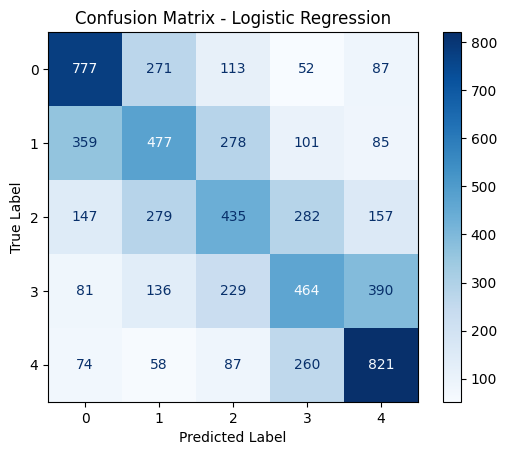

In [23]:
y_pred_lr = lr_model.predict(X_test_tfidf)
lr_accuracy = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", lr_accuracy)
print("Logistic Regression Classification Report:\n", classification_report(y_test, y_pred_lr))

# Tính confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)

# Vẽ confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.grid(False)
plt.show()

**Đánh giá RandomForest**

Random Forest Accuracy: 0.44153846153846155
Random Forest Report:
               precision    recall  f1-score   support

           0       0.51      0.60      0.55      1300
           1       0.38      0.29      0.33      1300
           2       0.40      0.29      0.34      1300
           3       0.42      0.29      0.35      1300
           4       0.45      0.72      0.56      1300

    accuracy                           0.44      6500
   macro avg       0.43      0.44      0.42      6500
weighted avg       0.43      0.44      0.42      6500



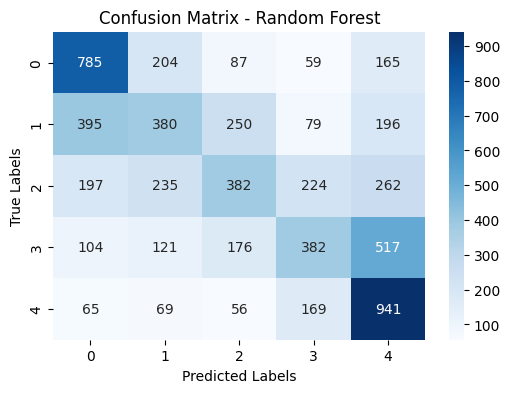

In [24]:
y_pred_rf_best = rf_model_best.predict(X_test_tfidf)
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf_best))
print("Random Forest Report:\n", classification_report(y_test, y_pred_rf_best))

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf_best)

# Visualization
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix - Random Forest')
plt.show()

**Đánh giá RoBERTa**

              precision    recall  f1-score   support

           1       0.68      0.63      0.65      1300
           2       0.51      0.54      0.53      1300
           3       0.50      0.49      0.49      1300
           4       0.54      0.53      0.53      1300
           5       0.68      0.71      0.70      1300

    accuracy                           0.58      6500
   macro avg       0.58      0.58      0.58      6500
weighted avg       0.58      0.58      0.58      6500



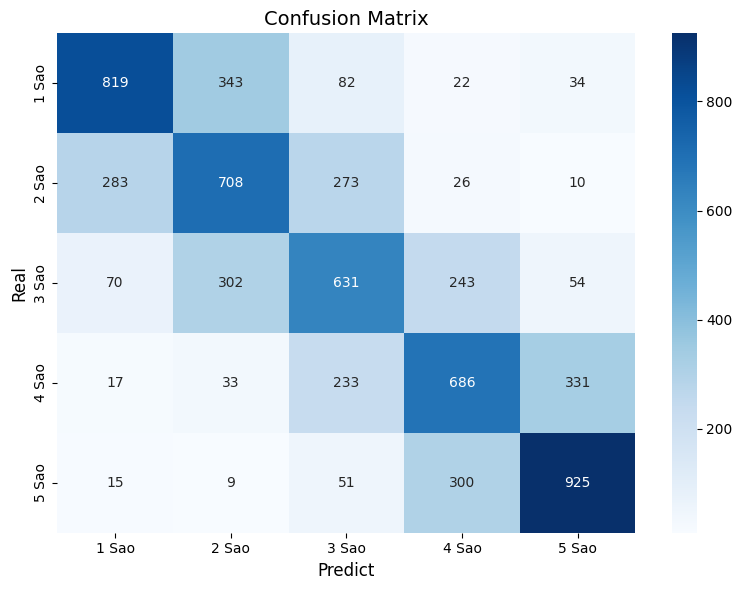

In [25]:
trainer.evaluate()
pred = trainer.predict(test_dataset)
y_pred = pred.predictions.argmax(axis=1)
print(classification_report(pred.label_ids, y_pred, target_names=["1", "2", "3", "4", "5"]))

pred_labels = np.argmax(pred.predictions, axis=-1).ravel()  # Làm phẳng
true_labels = pred.label_ids.ravel()  # Làm phẳng
cm = confusion_matrix(true_labels, pred_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predict', fontsize=12)
plt.ylabel('Real', fontsize=12)
plt.title('Confusion Matrix', fontsize=14)
plt.tight_layout()
plt.show()

In [41]:
import torch
checkpoints = ["/kaggle/working/results/checkpoint-500",
               "/kaggle/working/results/checkpoint-1000",
               "/kaggle/working/results/checkpoint-1500",
               "/kaggle/working/results/checkpoint-2000",
               "/kaggle/working/results/checkpoint-2500",
               "/kaggle/working/results/checkpoint-3000",
               "/kaggle/working/results/checkpoint-3500",
               "/kaggle/working/results/checkpoint-4000",
               "/kaggle/working/results/checkpoint-4500"]

for cp in checkpoints:
    model = RobertaForSequenceClassification.from_pretrained(cp, num_labels=5)
    models.append(model)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

text = "I’ve bought and replaced this piece of equipment three times and every time the part attaching the top grinder blade to the funnel fails because it’s made of cheap plastic. It works great other than that, but it sucks that I can’t get coffee this morning because somebody decided to spend 3 cents on a piece of plastic rather than 5."
true_label = 2  # Nhãn thực tế ban đầu

# 3. Tokenization
inputs = tokenizer(
    text,
    max_length=24,  # Giới hạn độ dài như trong hình ảnh
    padding='max_length',
    truncation=True,
    return_tensors='pt'
)

input_ids = inputs['input_ids'].to(device)
attention_mask = inputs['attention_mask'].to(device)
labels = torch.tensor([true_label]).to(device)

data = {
    "text": text,
    "input_ids": input_ids,
    "attention_mask": attention_mask,
    "targets": labels
}
print("=== Bước 1: Dữ liệu thô sau tokenization ===")
for key, value in data.items():
    print(f"{{'{key}': {value}}}")

# 4. Trích xuất embedding và logits từ mô hình đã huấn luyện
model.eval()
with torch.no_grad():
    outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
    logits = outputs.logits  # Tensor đầu ra trước softmax

print("\n=== Bước 2: Logits từ mô hình đã huấn luyện ===")
print(f"{{'logits': {logits}}}")

# 5. Áp dụng softmax để lấy xác suất
probabilities = torch.softmax(logits, dim=-1)
print("\n=== Bước 3: Xác suất sau softmax ===")
print(f"{{'probabilities': {probabilities}}}")

# 6. Dự đoán nhãn
predicted_label = torch.argmax(probabilities, dim=-1)
print("\n=== Bước 4: Nhãn dự đoán ===")
print(f"{{'predicted_label': {predicted_label}}}")

=== Bước 1: Dữ liệu thô sau tokenization ===
{'text': I’ve bought and replaced this piece of equipment three times and every time the part attaching the top grinder blade to the funnel fails because it’s made of cheap plastic. It works great other than that, but it sucks that I can’t get coffee this morning because somebody decided to spend 3 cents on a piece of plastic rather than 5.}
{'input_ids': tensor([[    0,   100,    17,    27,   548,  2162,     8,  4209,    42,  2125,
             9,  2104,   130,   498,     8,   358,    86,     5,   233, 39484,
             5,   299,  4435,     2]], device='cuda:0')}
{'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]],
       device='cuda:0')}
{'targets': tensor([2], device='cuda:0')}

=== Bước 2: Logits từ mô hình đã huấn luyện ===
{'logits': tensor([[ 4.6914,  2.2961, -1.1012, -2.9941, -2.9549]], device='cuda:0')}

=== Bước 3: Xác suất sau softmax ===
{'probabilities': tensor([[9.1313e-01, 8.

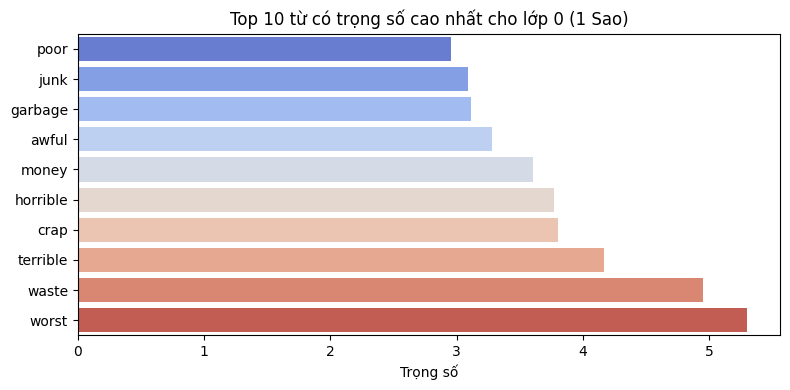

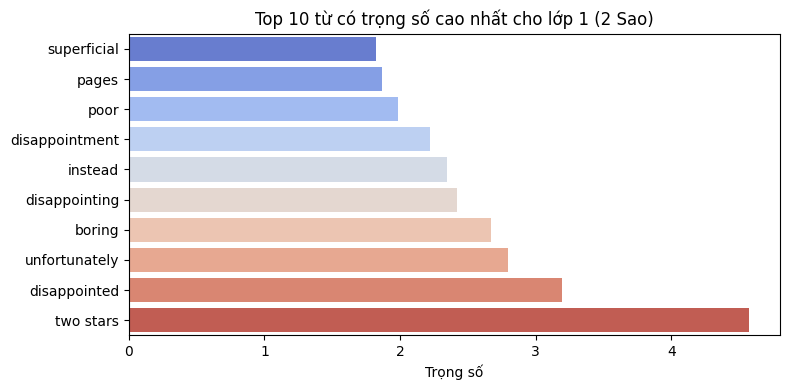

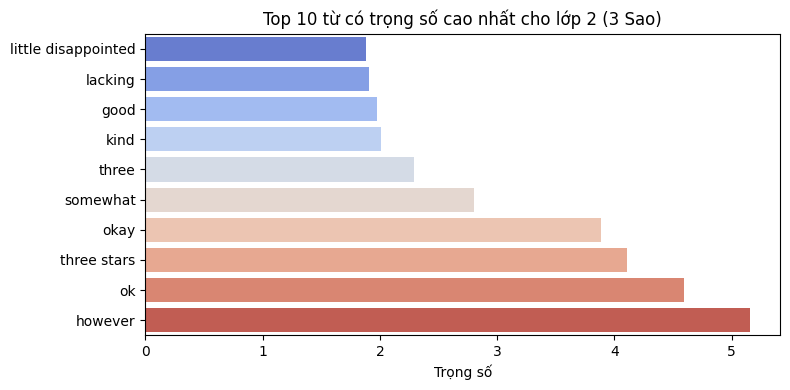

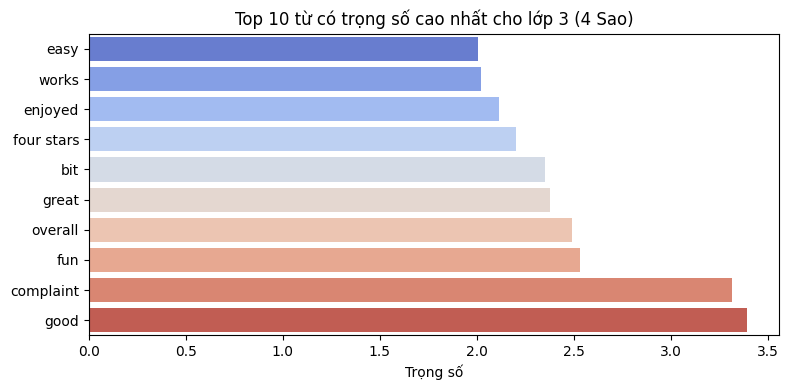

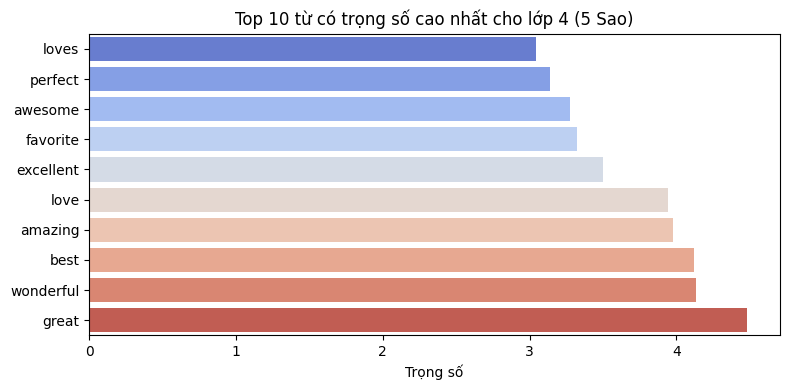

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lấy tên đặc trưng từ vectorizer
feature_names = vectorizer.get_feature_names_out()
topn = 10  # Số từ quan trọng nhất muốn hiển thị

# Duyệt qua từng lớp
for class_index in range(len(lr_model.classes_)):
    coefs = lr_model.coef_[class_index]
    top_indices = np.argsort(coefs)[-topn:]  # Chọn top n trọng số lớn nhất
    top_words = feature_names[top_indices]
    top_weights = coefs[top_indices]

    # Vẽ biểu đồ
    plt.figure(figsize=(8, 4))
    sns.barplot(x=top_weights, y=top_words, palette="coolwarm")
    plt.title(f"Top {topn} từ có trọng số cao nhất cho lớp {lr_model.classes_[class_index]} ({lr_model.classes_[class_index]+1} Sao)")
    plt.xlabel("Trọng số")
    plt.tight_layout()
    plt.show()


**Hiển thị các ví dụ sai**

In [42]:
# Duyệt qua các mẫu bị đoán sai
wrong_examples = []
for text, true, pred_label in zip(X_test_preprocessed, true_labels, pred_labels):
    if true != pred_label:
        wrong_examples.append((text, true, pred_label))

# In 10 ví dụ đầu tiên
for i, (text, true, pred_label) in enumerate(wrong_examples[:10]):
    print(f"❌ Example {i+1}")
    print(f"Text: {text}")
    print(f"True Label: {true}, Predicted: {pred_label}")
    print("-" * 50)

❌ Example 1
Text: rage little different standard stephen king book first infamous bachman books also stigma publication permanently stopped columbine shootings typical horror novel like psychological thriller book revolves around high school kid traumatic childhood eventually comes via several acts escalating violence teachers administrators school also takes entire classroom hostage bizarre interactions definitely good works stephen king admirable job exploring psyche tormented mentally ill individual make think little bit particularly context world live years first published chilling preview would happen columbine schools otherwise one kings worst books
True Label: 1, Predicted: 2
--------------------------------------------------
❌ Example 2
Text: gave much weight amazon reviews deciding book ron ashers colloquial tamil complete beginner soon spend year semirural tamil nadu want book get speed soon possible harts book good learning read unfortunately lot basic vocabulary like used b